# Xây dựng mô hình Naive Bayes trên dữ liệu phân loại nấm

Dữ liệu: `mushrooms.csv` trong cùng thư mục. Dự đoán `class`: `e` (ăn được) hoặc `p` (có độc), từ các đặc trưng phân loại. Dùng BernoulliNB của Scikit-learn sau khi mã hóa one-hot thành các cột 0/1.

Luồng thực hiện: đọc dữ liệu → chọn đặc trưng → chia train/test → điền giá trị phổ biến nhất và mã hóa one-hot → huấn luyện → dự đoán và đánh giá.

Tham khảo giải thuật: [Naive Bayes trong Scikit-learn](https://scikit-learn.org/stable/modules/naive_bayes.html).


## 0. Import thư viện


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


## 1. Chuẩn bị dữ liệu


In [2]:
df = pd.read_csv('mushrooms.csv')
print("Kích thước dữ liệu:", df.shape)
print(df.head().to_string(index=False))
print("\nSố lượng mẫu mỗi lớp:")
print(df['class'].value_counts().sort_index())
print("\nSố dòng trùng lặp:", df.duplicated().sum())


Kích thước dữ liệu: (8124, 23)
class cap-shape cap-surface cap-color bruises odor gill-attachment gill-spacing gill-size gill-color stalk-shape stalk-root stalk-surface-above-ring stalk-surface-below-ring stalk-color-above-ring stalk-color-below-ring veil-type veil-color ring-number ring-type spore-print-color population habitat
    p         x           s         n       t    p               f            c         n          k           e          e                        s                        s                      w                      w         p          w           o         p                 k          s       u
    e         x           s         y       t    a               f            c         b          k           e          c                        s                        s                      w                      w         p          w           o         p                 n          n       g
    e         b           s         w       t    l               f   

### 1.1. Chuyển ký hiệu thiếu thành NaN và tách nhãn

Ký hiệu `?` biểu thị giá trị chưa biết, được đổi thành NaN để điền thiếu sau khi chia train/test. Bước này chưa tính thống kê từ dữ liệu. Tách `class` khỏi X để tránh đưa đáp án vào đặc trưng. Các mã chữ được giữ dưới dạng phân loại, không coi là số có thứ tự.


In [3]:
X = df.drop(columns="class").replace("?", np.nan)
# Dùng object để xử lý thống nhất chuỗi và np.nan.
X = X.astype(object).where(X.notna(), np.nan)
y = df["class"]
print("Số đặc trưng:", X.shape[1])
print("\nGiá trị thiếu:")
print(X.isna().sum())


Số đặc trưng: 22

Giá trị thiếu:
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64


### 1.2. Chia dữ liệu theo 80/20 với random_state là 42


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Kích thước train/test:", X_train.shape, X_test.shape)
print("Tỉ lệ lớp (train):")
print(y_train.value_counts(normalize=True))
print("\nGiá trị thiếu (train):")
print(X_train.isna().sum())


Kích thước train/test: (6499, 22) (1625, 22)
Tỉ lệ lớp (train):
class
e    0.517926
p    0.482074
Name: proportion, dtype: float64

Giá trị thiếu (train):
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  1968
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64


### 1.3. Cấu hình điền thiếu và mã hóa phân loại

Điền thiếu bằng giá trị phổ biến nhất của từng cột rồi mã hóa one-hot thành các cột 0/1. `handle_unknown="ignore"` cho phép xử lý giá trị phân loại mới khi dự đoán. Giữ toàn bộ cột one-hot và không chuẩn hóa các cột nhị phân.

Các cột one-hot thuộc cùng một đặc trưng vẫn phụ thuộc nhau; đây là giới hạn của giả định độc lập có điều kiện trong mô hình cơ sở này.


In [5]:
from sklearn.preprocessing import OneHotEncoder

imputer = SimpleImputer(strategy="most_frequent")
encoder = OneHotEncoder(handle_unknown="ignore")


## 2. Tiền xử lý và huấn luyện Naive Bayes

Pipeline gồm điền thiếu, mã hóa one-hot và BernoulliNB. `alpha=1.0` là Laplace smoothing, giúp tránh xác suất bằng 0 cho sự kiện chưa xuất hiện trong train. `binarize=None` vì dữ liệu sau mã hóa đã là 0/1.

Mọi thống kê điền thiếu, danh mục mã hóa và tham số mô hình chỉ được học từ tập train.


In [6]:
from sklearn.naive_bayes import BernoulliNB

model = Pipeline([
    ("imputer", imputer),
    ("encoder", encoder),
    ("nb", BernoulliNB(alpha=1.0, binarize=None))
])
model.fit(X_train, y_train)
print("Đã huấn luyện Bernoulli Naive Bayes.")
print("Số cột sau mã hóa:", len(model.named_steps["encoder"].get_feature_names_out()))


Đã huấn luyện Bernoulli Naive Bayes.
Số cột sau mã hóa: 116


## 3. Dự đoán và đánh giá mô hình


Accuracy trên train: 0.9412217264194491
Accuracy trên test: 0.9335384615384615

Báo cáo phân loại:
              precision    recall  f1-score   support

     Ăn được     0.8963    0.9857    0.9389       842
      Có độc     0.9828    0.8774    0.9271       783

    accuracy                         0.9335      1625
   macro avg     0.9396    0.9316    0.9330      1625
weighted avg     0.9380    0.9335    0.9332      1625



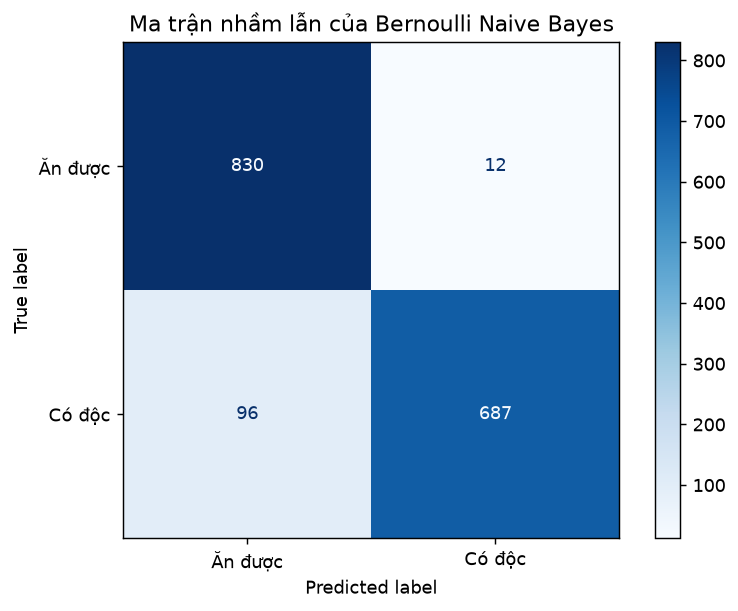

In [7]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

y_pred = model.predict(X_test)
print("Accuracy trên train:", model.score(X_train, y_train))
print("Accuracy trên test:", accuracy_score(y_test, y_pred))
print("\nBáo cáo phân loại:")
print(classification_report(
    y_test, y_pred,
    labels=['e', 'p'],
    target_names=['Ăn được', 'Có độc'],
    digits=4,
    zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=['e', 'p'],
    display_labels=['Ăn được', 'Có độc'],
    cmap="Blues"
)
plt.title("Ma trận nhầm lẫn của Bernoulli Naive Bayes")
plt.tight_layout()
plt.show()


## 4. Nhận xét

- **Độ chính xác:** Accuracy train đạt **94,12%**, test đạt **93,35%**, tương ứng dự đoán đúng **1517/1625 mẫu test**.
- **Kết quả lớp có độc:** Precision đạt **98,28%**, recall đạt **87,74%**, F1-score đạt **92,71%**; nhận diện đúng **687/783 mẫu** thuộc lớp này.
- **Ma trận nhầm lẫn:** Có **830 mẫu ăn được được dự đoán đúng**, **12 mẫu ăn được bị dự đoán thành có độc**, **96 mẫu có độc bị dự đoán thành ăn được** và **687 mẫu có độc được dự đoán đúng**.
- **Chênh lệch train/test:** Accuracy train cao hơn test **0.77 điểm phần trăm**. Một lần chia dữ liệu chưa đủ để khẳng định mô hình có hoặc không overfitting.

**Kết luận:** Bernoulli Naive Bayes có thể phân loại dữ liệu nấm sau xử lý giá trị thiếu và mã hóa one-hot. Cần đọc riêng recall của lớp có độc và số mẫu có độc bị nhầm thành ăn được. Kết quả chỉ phản ánh bài thực hành trên bộ dữ liệu đã cho và lần chia train/test hiện tại.